In [2]:
import torch
import time
import os
import matplotlib.pyplot as plt

from tqdm import tqdm

from model.deit_tiny.model_deit_tiny import (
    create_model,
    create_loss_function,
    create_optimizer,
    show_model_config,
    show_model_summary,
    EPOCHS,
    DEVICE
)

from preprocesing_data.data_loader import create_data_loaders

In [3]:
# Load dataset
train_loader, val_loader, test_loader, class_names, num_classes = (
    create_data_loaders()
)

print("========================================")
print("INFORMASI DATASET")
print("========================================")
print("Jumlah kelas      :", num_classes)
print("Data training     :", len(train_loader.dataset))
print("Data validation   :", len(val_loader.dataset))
print("Data testing      :", len(test_loader.dataset))
print("========================================")

# Konfigurasi model
show_model_config()

# Inisialisasi model
model = create_model(num_classes)

criterion = create_loss_function()
optimizer = create_optimizer(model)

show_model_summary(model)

# Folder hasil
os.makedirs("results/deit_tiny", exist_ok=True)

BEST_MODEL_PATH = "results/deit_tiny/best_model.pth"
LAST_MODEL_PATH = "results/deit_tiny/last_model.pth"

# History training
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

print("\nModel dan dataset berhasil disiapkan.")


INFORMASI DATASET IKAN
Total gambar ditemukan : 4411
Total kelas ikan       : 483
Gambar tidak ditemukan: 0
Baris indeks tidak valid: 0

PEMBAGIAN DATASET
Training   : 2821 gambar
Validation : 594 gambar
Testing    : 996 gambar
-----------------------------------
Persentase Training   : 63.95%
Persentase Validation : 13.47%
Persentase Testing    : 22.58%
-----------------------------------
Total kelas           : 483
Kelas training        : 483
Kelas validation      : 483
Kelas testing         : 483

DATA LOADER BERHASIL DIBUAT
Jumlah kelas : 483
Batch size   : 16
Image size   : 224
Device       : cpu
INFORMASI DATASET
Jumlah kelas      : 483
Data training     : 2821
Data validation   : 594
Data testing      : 996
          KONFIGURASI DEIT-TINY
Nama Model       : DeiT-Tiny
Arsitektur       : deit_tiny_patch16_224
Image Size       : 224
Batch Size       : 16
Epoch            : 5
Learning Rate    : 0.0001
Weight Decay     : 0.0001
Pretrained       : True
Device           : cpu


Total Parameters     : 5,617,635
Trainable Parameters : 93,219

Model dan dataset berhasil disiapkan.


In [ ]:
train_loader, val_loader, test_loader, class_names, num_classes = (
    create_data_loaders()
)

print("========================================")
print("INFORMASI DATASET")
print("========================================")

print("Jumlah kelas       :", num_classes)
print("Data training      :", len(train_loader.dataset))
print("Data validation    :", len(val_loader.dataset))
print("Data testing       :", len(test_loader.dataset))

print("Jumlah batch train :", len(train_loader))
print("Jumlah batch val   :", len(val_loader))
print("Jumlah batch test  :", len(test_loader))

print("========================================")

In [4]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Training"):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    return total_loss / total, correct / total


def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Validation"):

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    return total_loss / total, correct / total

In [5]:
print("========================================")
print("       TRAINING MODEL DEIT-TINY")
print("========================================")

for epoch in range(EPOCHS):

    start_time = time.time()

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion
    )

    # Simpan history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    epoch_time = time.time() - start_time

    print("\nHASIL EPOCH")
    print("----------------------------------------")
    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy * 100:.2f}%")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy * 100:.2f}%")
    print(f"Epoch Time     : {epoch_time:.2f} detik")

    # Simpan model terbaik
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_accuracy": val_accuracy,
            "val_loss": val_loss,
            "class_names": class_names
        }, BEST_MODEL_PATH)

        print("Best model berhasil disimpan!")

    print("========================================")

# Simpan model terakhir
torch.save({
    "epoch": EPOCHS,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "history": history,
    "class_names": class_names
}, LAST_MODEL_PATH)

print("\nTRAINING SELESAI")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")

       TRAINING MODEL DEIT-TINY

Epoch [1/5]


Validation: 100%|██████████| 38/38 [00:24<00:00,  1.57it/s]



HASIL EPOCH
----------------------------------------
Train Loss     : 6.1994
Train Accuracy : 0.39%
Val Loss       : 6.0906
Val Accuracy   : 1.01%
Epoch Time     : 173.81 detik
Best model berhasil disimpan!

Epoch [2/5]


Validation: 100%|██████████| 38/38 [00:29<00:00,  1.29it/s]



HASIL EPOCH
----------------------------------------
Train Loss     : 5.8053
Train Accuracy : 1.88%
Val Loss       : 5.8996
Val Accuracy   : 2.19%
Epoch Time     : 202.13 detik
Best model berhasil disimpan!

Epoch [3/5]


Validation: 100%|██████████| 38/38 [00:31<00:00,  1.20it/s]



HASIL EPOCH
----------------------------------------
Train Loss     : 5.5054
Train Accuracy : 5.10%
Val Loss       : 5.7294
Val Accuracy   : 4.55%
Epoch Time     : 180.42 detik
Best model berhasil disimpan!

Epoch [4/5]


Validation: 100%|██████████| 38/38 [01:50<00:00,  2.92s/it]



HASIL EPOCH
----------------------------------------
Train Loss     : 5.2399
Train Accuracy : 11.06%
Val Loss       : 5.5748
Val Accuracy   : 7.41%
Epoch Time     : 386.92 detik
Best model berhasil disimpan!

Epoch [5/5]


Validation: 100%|██████████| 38/38 [00:36<00:00,  1.04it/s]



HASIL EPOCH
----------------------------------------
Train Loss     : 5.0128
Train Accuracy : 14.89%
Val Loss       : 5.4304
Val Accuracy   : 9.60%
Epoch Time     : 336.20 detik
Best model berhasil disimpan!

TRAINING SELESAI
Best Validation Accuracy: 9.60%


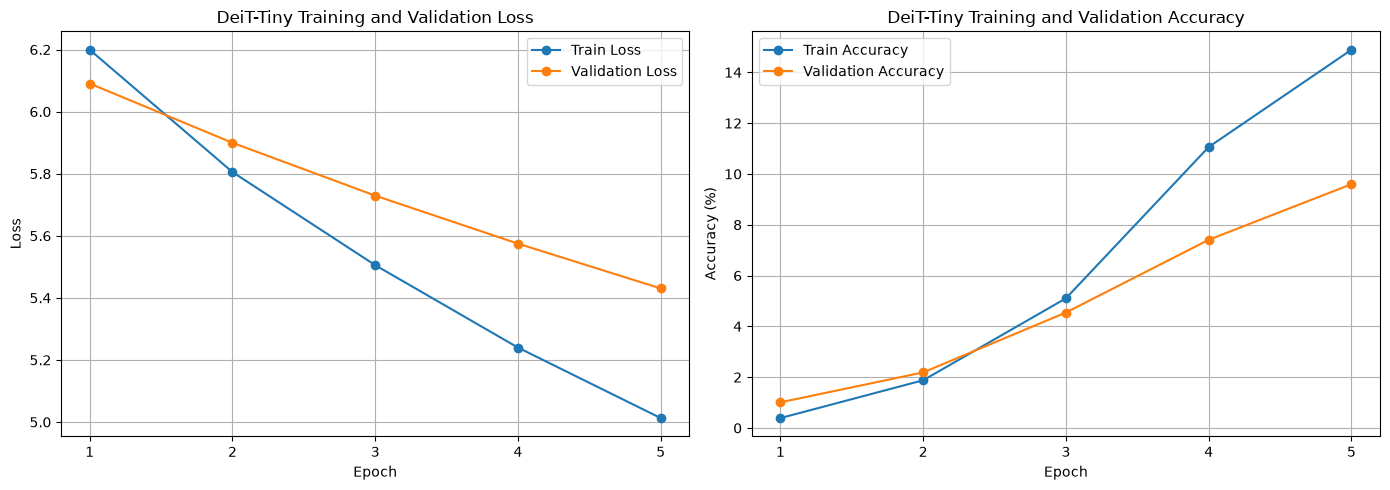

In [7]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Grafik Loss
plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["train_loss"],
         marker="o", label="Train Loss")

plt.plot(epochs_range, history["val_loss"],
         marker="o", label="Validation Loss")

plt.title("DeiT-Tiny Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

# Grafik Accuracy
plt.subplot(1, 2, 2)

plt.plot(epochs_range,
         [x * 100 for x in history["train_accuracy"]],
         marker="o", label="Train Accuracy")

plt.plot(epochs_range,
         [x * 100 for x in history["val_accuracy"]],
         marker="o", label="Validation Accuracy")

plt.title("DeiT-Tiny Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "results/deit_tiny/training_history.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()